###                                     Modularity on the Karate Club Graph

### Importing the Karate Club graph

I imported the libraries needed for the analysis:

     NumPy for the matrix operations
     Matplotlib to visualize the graph
     Installed networkx for importing the graph

I then loaded Zachary’s Karate Club network. This is a built-in social network of 34 members of a karate club, with 78 edges representing the connection. The club later split into two factions, one around the instructor “Mr. Hi” and one around the administrator “Officer”.

	 	 	 Karate Club Graph 	 
Nodes: 34, Edges: 78


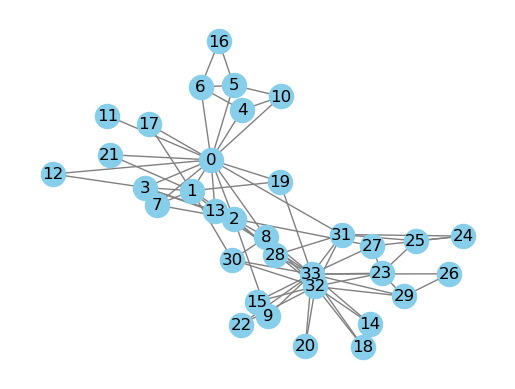

In [13]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
G = nx.karate_club_graph()
A = nx.to_numpy_array(G)

print("\t \t \t Karate Club Graph \t ")
print(f"Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}")

nx.draw_networkx(G, nx.spring_layout(G, seed=42), node_color="skyblue", edge_color="gray")
plt.axis("off")
plt.show()

### Buliding up the adjacency matrix $ A $

Adjacency Matrix is a matrix to represent connections between nodes in a network

In [14]:
A = nx.to_numpy_array(G, weight=None)
np.set_printoptions(linewidth=250)
print(A)

[[0. 1. 1. ... 1. 0. 0.]
 [1. 0. 1. ... 0. 0. 0.]
 [1. 1. 0. ... 0. 1. 0.]
 ...
 [1. 0. 0. ... 0. 1. 1.]
 [0. 0. 1. ... 1. 0. 1.]
 [0. 0. 0. ... 1. 1. 0.]]


### Defining $ k_i $  and $ m $:

$ k_i $ is the degree of node i. $ m $ is the total number of edges in the network.

In [15]:
k = A.sum(axis=1)   
m = A.sum() / 2    

print(f"m = {m}")          
print(f"k[:8] = {k[:8]}")   
print(f"max degree = {k.max()} (node {k.argmax()})")

m = 78.0
k[:8] = [16.  9. 10.  6.  3.  4.  4.  4.]
max degree = 17.0 (node 33)


### Modularity matrix: 

I then computed the modularity matrix B:

$$B_{ij} = A_{ij} - \frac{k_i k_j}{2m}$$

where:
      $ A $ is the Adjacency Matrix
      $$ \frac{k_i k_j}{2m} $$ is the number of edges between i and j


In [16]:
B = A - np.outer(k, k) / (2 * m)

print(f"B shape: {B.shape}")
np.set_printoptions(precision=4, suppress=True, linewidth=250)
print(B)

B shape: (34, 34)
[[-1.641   0.0769 -0.0256 ...  0.3846 -1.2308 -1.7436]
 [ 0.0769 -0.5192  0.4231 ... -0.3462 -0.6923 -0.9808]
 [-0.0256  0.4231 -0.641  ... -0.3846  0.2308 -1.0897]
 ...
 [ 0.3846 -0.3462 -0.3846 ... -0.2308  0.5385  0.3462]
 [-1.2308 -0.6923  0.2308 ...  0.5385 -0.9231 -0.3077]
 [-1.7436 -0.9808 -1.0897 ...  0.3462 -0.3077 -1.8526]]


### Extracting a group’s block of the modularity matrix

When a group of nodes $g$ is considered for splitting, only the relationships within that group matter. So I define a sub-matrix of $B$ with rows and columns:

$$B^{(g)}_{ij} = B_{ij}, \qquad i, j \in g$$

For the full node set this is just $B$.

In [17]:
def get_part(nodes):
    """Rows/columns of B for this group (the plain block)."""
    return B[np.ix_(nodes, nodes)]

### Leading eigenvalue and eigenvector of a group

To decide how a group of nodes $g$ splits, I need the leading eigenpair of its block of the modularity matrix, $B^{(g)}$, which get_part extracts. The function top_eigen(nodes) computes it:

It builds the block $B^{(g)}$ for the group.
It diagonalizes the block with eigh, which is meant for symmetric matrices and returns the eigenvalues in ascending order. The last one is therefore the largest.
It returns the largest eigenvalue $\lambda_1$ and its eigenvector $u$:
$$B^{(g)}\, u = \lambda_1\, u, \qquad \lambda_1 = \max_k \lambda_k$$

The two outputs are used in different ways:

$\lambda_1$ is the stopping test. If $\lambda_1 \le 0$, no split of the group can increase modularity, so the group is indivisible.
$u$ gives the split. It has one entry per node. Nodes whose entries share a sign are connected more than chance predicts, so they go in the same community. Positive entries form one community and negative entries the other.

In [24]:
import numpy.linalg as al
def top_eigen(nodes):
    vals, vecs = al.eigh(get_part(nodes))
    return vals[-1], vecs[:, -1]

### Computing modularity Q

The modularity of a partition measures how much denser the communities are than a random network with the same degrees would give:

$$Q = \frac{1}{2m}\sum_{c}\;\sum_{i,\,j \in c} B_{ij}$$

where $m$ is the number of edges and $B_{ij} = A_{ij} - \frac{k_i k_j}{2m}$.

The function modularity does this in two steps:

Pairs of nodes in different communities are left out, so only the within-community pairs count. A high $Q$ means the communities have more internal connections than chance predicts. If all nodes sit in one community, the sum is over every entry of $B$, which is zero because the rows of $B$ sum to zero. That gives $Q = 0$, and this value is the baseline at iteration 0. I call this function after every round of splitting to record $Q$ for each iteration

In [25]:
def modularity(partition):
    return sum(B[np.ix_(c, c)].sum() for c in partition) / (2 * m)

### Splitting a group in two

I divide a group of nodes into two communities using the leading eigenpair of the group’s block $B^{(g)}$ from top_eigen.

1. Stopping rule. If $\lambda_1 \le 10^{-10}$, no split can increase modularity, so the group is indivisible and the function returns None.

2. Splitting by sign. Each entry $u_i$ is a score for node $i$. Nodes whose scores share a sign are connected more than chance predicts, so they go together:

$u_i > T$: the node joins the plus group
$u_i < -T$: the node joins the minus group

3. Undecided nodes. A node with $|u_i| \le T$ (I use $T = 0.03$) has a score so close to zero that its sign is unreliable. Instead, I compare its total connection strength to each side:

$$\text{to\_plus} = \sum_{j \in \text{plus}} B_{ij}, \qquad \text{to\_minus} = \sum_{j \in \text{minus}} B_{ij}$$

The node joins the side with the larger total. Since $B_{ij} > 0$ means a pair is connected more than chance, a larger total means a stronger tie to that side. A tie goes to the plus group.

4. No real split. If one side ends up empty, nothing was divided, so the function returns None. This is what stops the four communities of iteration 2: in each of them every entry of $u$ has the same sign, so one side is empty and the group is final even though $\lambda_1 > 0$.

Otherwise the function returns the two new groups (plus, minus). The recursion calls it on every group in each iteration until no group can be split.

In [26]:
T = 0.03   # eigenvector entries with |u| <= T are "undecided"

def split_group(nodes):
    lam, u = top_eigen(nodes)
    if lam <= 1e-10:                       # stopping rule
        return None

    plus  = [n for n, x in zip(nodes, u) if x >  T]
    minus = [n for n, x in zip(nodes, u) if x < -T]

    # undecided nodes join the side with the larger total B-weight
    for n, x in zip(nodes, u):
        if abs(x) <= T:
            to_plus  = sum(B[n][j] for j in plus  if j != n)
            to_minus = sum(B[n][j] for j in minus if j != n)
            (plus if to_plus >= to_minus else minus).append(n)

    if not plus or not minus:              # everyone on one side
        return None
    return plus, minus

all_history = []
current = [list(range(34))]
all_history.append((current, modularity(current)))

while True:
    new_partition, any_split = [], False
    for g in current:
        result = split_group(g)
        if result is None:
            new_partition.append(g)
        else:
            new_partition.extend(result)
            any_split = True
    if not any_split:
        break
    current = new_partition
    all_history.append((current, modularity(current)))

### The loop ran for two rounds and stopped after:

### What does the split show? 

Iteration 1: the first split gives groups of 16 and 18 nodes. Compared with the real faction split, only node 8 is on the wrong side.

Iteration 2: each group splits again, giving 4 communities. Node 11 stays with node 0 because its near-zero eigenvector entry is treated as undecided and its modularity weight points to node 0's group.

With the handout's plain sign rule there would be a third iteration that isolates node 11, giving 5 communities with Q = 0.4094.
Q rises at every step.

Community,Size,λ₁,Status,Members
0,34,4.9771,splits next,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33"
Community,Size,λ₁,Status,Members
0,16,2.9441,splits next,"0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21"
1,18,2.5041,splits next,"8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33"
Community,Size,λ₁,Status,Members
0,11,2.5813,final,"0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21"
1,5,2.1470,final,"4, 5, 6, 10, 16"
2,5,1.8759,final,"24, 25, 27, 28, 31"
3,13,2.3563,final,"8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33"

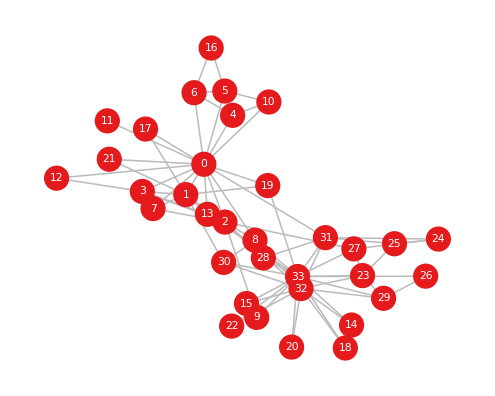
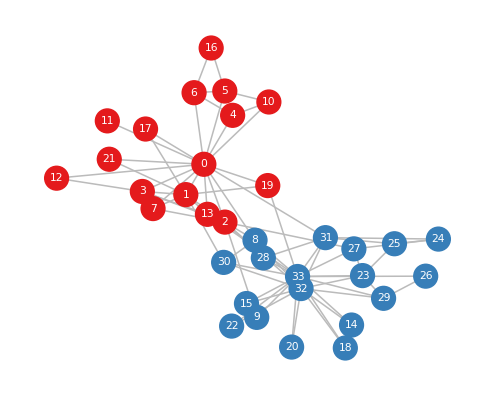
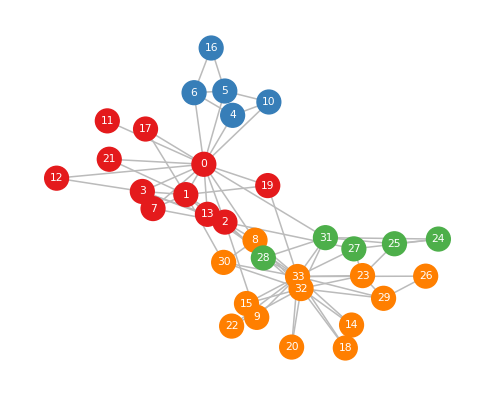

In [27]:
import io, base64
from IPython.display import display, HTML
import matplotlib.pyplot as plt

# ---------- styling (moderate size) ----------
css = """
<style>
.row { display:flex; align-items:center; gap:24px; margin-bottom:12px; }
.it  { font-family: 'Segoe UI', 'Helvetica Neue', Arial, sans-serif;
       font-size: 15px; font-weight: 600; color: #1a237e;
       margin: 0 0 5px 0; line-height: 1.3; }
.it .q { background:#e8eaf6; color:#283593; padding:1px 10px;
         border-radius:10px; font-size:13px; margin-left:8px; }
table.t { font-family: 'Segoe UI', 'Helvetica Neue', Arial, sans-serif;
          font-size: 13px; border-collapse: collapse; width: auto;
          border: 1px solid #c5cae9; }
table.t th { background:#3949ab; color:white; padding:4px 10px;
             text-align:center; font-weight:600; font-size:13px; }
table.t td { padding:3px 10px; text-align:center; line-height:1.3;
             border-bottom:1px solid #e8eaf6; }
table.t tr:nth-child(even) td { background:#f5f6fc; }
table.t td.m { text-align:left; font-family: Consolas, 'Courier New', monospace;
               font-size:12px; color:#37474f; }
.fin { background:#e8f5e9; color:#2e7d32; padding:1px 9px;
       border-radius:8px; font-weight:600; font-size:12px; }
.nxt { background:#fff3e0; color:#e65100; padding:1px 9px;
       border-radius:8px; font-weight:600; font-size:12px; }
</style>
"""

# ---------- graph settings ----------
pos = nx.spring_layout(G, seed=42)    # one fixed layout for every iteration
palette = ["#e41a1c", "#377eb8", "#4daf4a", "#ff7f00", "#984ea3", "#a65628", "#f781bf", "#999999"]

def table_html(i):
    partition, Q = all_history[i]
    h = (f"<div class='it'>Iteration {i} &nbsp;·&nbsp; {len(partition)} communities"
         f"<span class='q'>Q = {Q:.4f}</span></div>")
    h += ("<table class='t'><tr><th>Community</th><th>Size</th><th>λ₁</th>"
          "<th>Status</th><th>Members</th></tr>")
    for c, comm in enumerate(partition):
        members = sorted(comm)
        lam, _ = top_eigen(members)
        if split_group(members) is not None:
            status = "<span class='nxt'>splits next</span>"
        else:
            status = "<span class='fin'>final</span>"
        h += (f"<tr><td>{c}</td><td>{len(members)}</td><td>{lam:.4f}</td>"
              f"<td>{status}</td><td class='m'>{', '.join(map(str, members))}</td></tr>")
    return h + "</table>"

def graph_img(i, width=330):
    """Draw the graph for iteration i and return it as an <img> tag."""
    partition, Q = all_history[i]
    label = {n: c for c, comm in enumerate(partition) for n in comm}
    colors = [palette[label[n] % len(palette)] for n in G.nodes()]
    fig = plt.figure(figsize=(4.5, 3.6))
    nx.draw_networkx(G, pos, node_color=colors, node_size=240,
                     edge_color="#bbbbbb", font_size=7, font_color="white")
    plt.axis("off")
    plt.tight_layout()
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110)
    plt.close(fig)                       # stops the plot showing a second time
    b64 = base64.b64encode(buf.getvalue()).decode()
    return f"<img src='data:image/png;base64,{b64}' width='{width}'>"

html = css
for i in range(len(all_history)):
    html += f"<div class='row'><div>{table_html(i)}</div>{graph_img(i)}</div>"

display(HTML(html))

### Computing the node metrics for every iteration

This step computes degree, betweenness, closeness and clustering for all 34 nodes, once for each iteration.

Given the partition at one iteration, the function goes through its communities one at a time:

It keeps only the nodes in that community and the edges between them, so all edges that run between communities are dropped.

1. Degree centrality:

   $$C_D(i)=\frac{k_i}{n-1}$$

The number of direct neighbors, divided by the maximum possible ($n-1$, everyone else). It ranges from 0 to 1, and 1 means the node is connected to every other node.

It counts a person’s direct friends, as a fraction of everyone else in their group. Node 0 (Mr. Hi) is friends with 16 of the 33 others, which gives 0.485 in the whole graph. This is the most popular person in the room.

2. Betweenness centrality:

   $$C_B(i)=\sum_{s\neq i\neq t}\frac{\sigma_{st}(i)}{\sigma_{st}}$$
$\sigma_{st}$ is the number of shortest paths from $s$ to $t$.
$\sigma_{st}(i)$ is how many of them pass through $i$.
The sum runs over unordered pairs $\{s,t\}$ that don’t include $i$.

Normalized for an undirected graph, which is what NetworkX does by default:

$$C_B^{\text{norm}}(i)=\frac{C_B(i)}{(n-1)(n-2)/2}$$

The result is between 0 and 1. High values are nodes that act as bridges, and a node on no shortest path scores 0.

Betweenness measures how often you are on the route. A person who connects two otherwise separate friend groups scores high, even without many friends. Node 2 scored 0.144 in the whole graph because it linked the two factions. Once we split the groups and cut the links between them, it fell to about 0.002.

3. Closeness centrality:

$$C_C(i)=\frac{n-1}{\sum_{j\neq i} d(i,j)}$$

This is the inverse of the average distance to all other nodes. If everyone is one step away, the sum is $n-1$ and $C_C = 1$. It assumes the graph is connected, which was true for every community in your iterations.
Node 0 has 0.569 in the whole graph and 1.0 in iteration 2, since it is directly connected to every member of its small community.

4. Clustering coefficient:

 $$C(i)=\frac{2\,T_i}{k_i(k_i-1)}$$
$T_i$ is the number of triangles through $i$, which equals the number of edges among its neighbors.
$\frac{k_i(k_i-1)}{2}$ is the number of possible edges among its $k_i$ neighbors.

Node 7 has 1.0 because its friends all know each other. Node 0 has only 0.150, since it knows many people who don’t know each other (it spans several groups).

### Iteration 0: 

In [28]:
import pandas as pd

def node_metrics(partition):
    """Each metric for every node, computed inside the node's own community."""
    deg, bet, clo, clu = {}, {}, {}, {}
    for comm in partition:
        H = G.subgraph(comm)                       # only the edges inside this community
        deg.update(nx.degree_centrality(H))
        bet.update(nx.betweenness_centrality(H))
        clo.update(nx.closeness_centrality(H))
        clu.update(nx.clustering(H))
    return deg, bet, clo, clu

names = ["Degree", "Betweenness", "Closeness", "Clustering"]
tables = {n: pd.DataFrame(index=range(34)) for n in names}    # nodes x iterations

for i, (partition, Q) in enumerate(all_history):
    for name, values in zip(names, node_metrics(partition)):
        tables[name][f"Iter {i}"] = pd.Series(values)

pd.set_option("display.max_rows", None)

per_iter = {}
for i in range(len(all_history)):
    per_iter[i] = pd.DataFrame({name: tables[name][f"Iter {i}"] for name in names}).round(3)
    per_iter[i].index.name = "Node"

print("Iteration 0: 1 community")
display(per_iter[0])

Iteration 0: 1 community


,Degree,Betweenness,Closeness,Clustering
Node,,,,
0,0.485,0.438,0.569,0.150
1,0.273,0.054,0.485,0.333
2,0.303,0.144,0.559,0.244
3,0.182,0.012,0.465,0.667
4,0.091,0.001,0.379,0.667
5,0.121,0.030,0.384,0.500
6,0.121,0.030,0.384,0.500
7,0.121,0.000,0.440,1.000
8,0.152,0.056,0.516,0.500


### Iteration 2

In [29]:
print(f"Iteration 1: {len(all_history[1][0])} communities, Q = {all_history[1][1]:.4f}")
display(per_iter[1])

Iteration 1: 2 communities, Q = 0.3715


,Degree,Betweenness,Closeness,Clustering
Node,,,,
0,0.933,0.690,0.938,0.187
1,0.533,0.074,0.652,0.429
2,0.333,0.002,0.577,0.900
3,0.400,0.021,0.600,0.667
4,0.200,0.003,0.556,0.667
5,0.267,0.065,0.577,0.500
6,0.267,0.065,0.577,0.500
7,0.267,0.000,0.556,1.000
8,0.176,0.000,0.515,1.000


### Iteration 2: 

In [30]:
print(f"Iteration 2: {len(all_history[2][0])} communities, Q = {all_history[2][1]:.4f}")
display(per_iter[2])

Iteration 2: 4 communities, Q = 0.4174


,Degree,Betweenness,Closeness,Clustering
Node,,,,
0,1.000,0.483,1.000,0.289
1,0.800,0.172,0.833,0.429
2,0.500,0.006,0.667,0.900
3,0.600,0.050,0.714,0.667
4,0.500,0.083,0.667,0.000
5,0.750,0.250,0.800,0.333
6,0.750,0.250,0.800,0.333
7,0.400,0.000,0.625,1.000
8,0.250,0.000,0.571,1.000


### How the node metrics evolve across iterations?

To see how the community structure affects each node’s importance, I plotted the four metrics against the iteration number (0, 1, 2).

Figure 1: metric evolution. There is one panel per metric: degree, betweenness, closeness and clustering. Each panel has:

a dashed black line for the average over all 34 nodes
one colored line for each of five key nodes: the two faction leaders 0 and 33, the other hub 32, and the two nodes that bridge the factions, 2 and 8

Plotting all 34 nodes would be unreadable, so I follow a few representative nodes and show the overall trend with the average.

Figure 2: heatmaps (optional). One heatmap per metric, with nodes as rows and iterations as columns, shows every node at once. This makes it easy to spot which nodes change a lot and which stay constant.

What the plots show

Degree and closeness rise because each community is smaller than the whole network. A node is directly connected to a larger share of its group, and distances inside the group are shorter. Nodes 0 and 33 reach 1.0 at iteration 2 and remain the most central throughout.
Betweenness drops for the bridge nodes. Nodes 2 and 8 fall to about 0 after the first split, because their role as links between the two factions disappears once the edges between communities are removed. 

Nodes 0 and 33 keep high betweenness, since they are hubs inside their own communities.

Clustering rises for bridge-like nodes. Nodes 2 and 8 jump to roughly 0.9 to 1.0 at iteration 1, because inside their own community their neighbors are tightly interlinked. The hubs stay low, since they connect many members who do not know each other. The average dips slightly at iteration 2 as some nodes lose the triangles they were part of.

Splitting the network into communities reveals two kinds of importance. Hubs stay central at every level, while bridge nodes are only important in the whole network and lose their prominence once the network is divided.

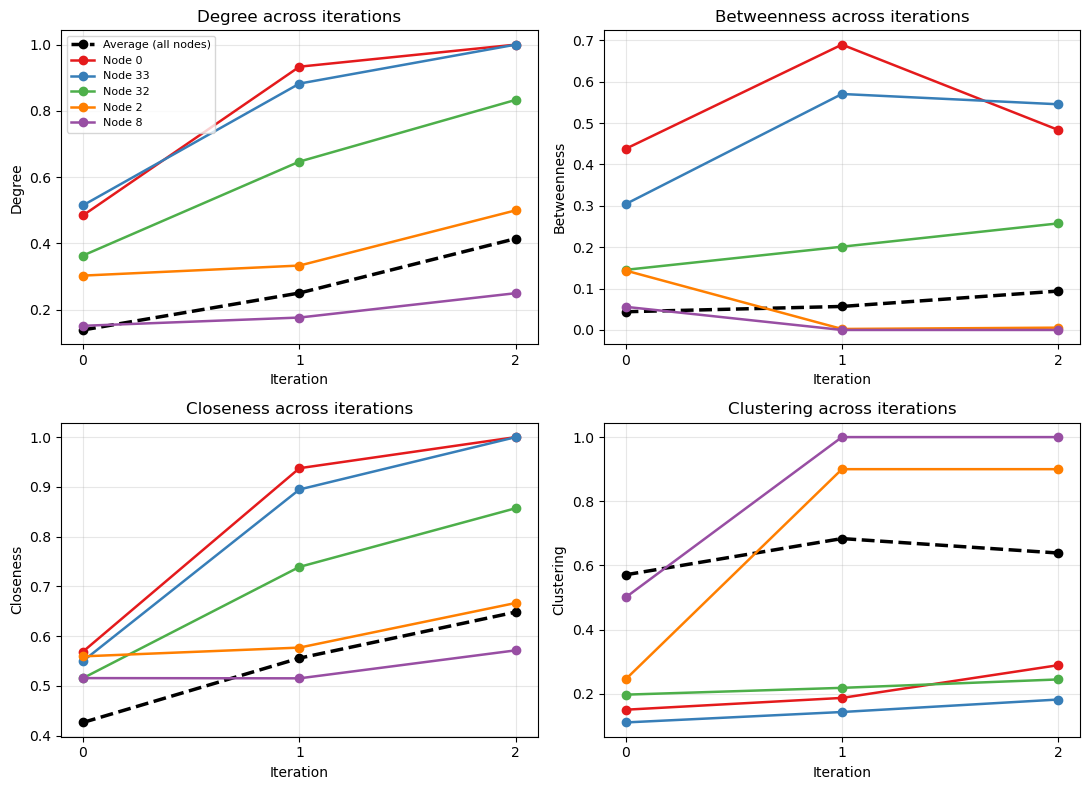

In [31]:
import matplotlib.pyplot as plt

iters = list(range(len(all_history)))
key_nodes = [0, 33, 32, 2, 8]       # hubs (0, 33, 32) and bridge nodes (2, 8)
colors = {0: "#e41a1c", 33: "#377eb8", 32: "#4daf4a", 2: "#ff7f00", 8: "#984ea3"}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, name in zip(axes.ravel(), names):
    df = tables[name]                                    # nodes x iterations
    ax.plot(iters, df.mean().values, color="black", lw=2.5, ls="--",
            marker="o", label="Average (all nodes)")
    for n in key_nodes:
        ax.plot(iters, df.loc[n].values, marker="o", lw=1.8,
                color=colors[n], label=f"Node {n}")
    ax.set_title(f"{name} across iterations")
    ax.set_xlabel("Iteration")
    ax.set_ylabel(name)
    ax.set_xticks(iters)
    ax.grid(alpha=0.3)

axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Summary

**Goal.** Detect multiple communities in Zachary's Karate Club network by recursive spectral modularity partitioning. Then track how four node metrics (degree, betweenness, closeness, clustering) change as the communities are revealed.

**1. Data.** The Karate Club graph has 34 members (nodes) and 78 friendships (edges). I used the unweighted adjacency matrix $A$, with $A_{ij}=1$ if members $i$ and $j$ are friends and 0 otherwise. From it I computed the degrees $k_i$ and the number of edges $m = 78$.

**2. Modularity matrix.** I built

$$B_{ij} = A_{ij} - \frac{k_i k_j}{2m}$$

which compares each observed connection with the number expected in a random network with the same degrees. $B_{ij}>0$ means two members are connected more than chance predicts. The modularity of a partition is

$$Q = \frac{1}{2m}\sum_{c}\sum_{i,j\in c} B_{ij}$$

so a high $Q$ means the communities are denser than chance. Putting everyone in one community gives $Q = 0$.

**3. Spectral splitting.** For a group of nodes, I take its block of $B$ and find its leading eigenvalue $\lambda_1$ and eigenvector $u$. If $\lambda_1 \le 10^{-10}$, the group cannot be split. Otherwise the signs of the entries of $u$ divide it into two groups. Entries with $|u_i| \le 0.03$ are "undecided" and join the side they are more strongly connected to. If one side ends up empty, the group is final.

**4. Recursion.** Starting with all nodes in one community, each iteration applies the split to every group that can be split and saves the partition and its $Q$. The process stopped after two rounds:

| Iteration | Communities | Q |
|---|---|---|
| 0 | 1 | 0.0000 |
| 1 | 2 (sizes 16 and 18) | 0.3715 |
| 2 | 4 (sizes 11, 5, 5 and 13) | 0.4174 |

I displayed a table and a colored graph for each iteration, using one fixed layout so that nodes stay in place.

**5. Comparison with the real split.** The first split matches the real Mr. Hi / Officer division for 33 of 34 members. The one exception is node 8, who has friends on both sides. The four final communities are sub-groups nested inside the two real factions.

**6. Node metrics.** For each iteration I computed the four metrics for all 34 nodes inside each community's subgraph, so that only edges within communities count. (On the whole graph they would be identical at every iteration.) Iteration 0 is the full-graph baseline.

- **Degree centrality** $\frac{k_i}{n-1}$: the fraction of the group a node is connected to
- **Betweenness centrality:** how often a node lies on shortest paths between other members
- **Closeness centrality** $\frac{n-1}{\sum_j d(i,j)}$: how near a node is to everyone else
- **Clustering coefficient** $\frac{2T_i}{k_i(k_i-1)}$: the fraction of a node's neighbors that are also connected to each other


**Conclusion.** 

Recursive spectral partitioning recovers the known factions with one misclassified member and then reveals finer sub-communities ($Q = 0.4174$). Hubs stay central at every level, while bridge nodes are important only in the whole network. So community structure determines not only who is central but why.

**Limitations.** 

The splitting is binary and greedy, with no refinement step. The threshold $T$ is a heuristic. Metrics are normalized by community size, so the trends are more meaningful than raw magnitudes. The results come from one small network.



### In general:

I used Claude AI to guide me through the process and to help me with the code. Some of the errors I noticed and fixed along the way:

- **Edge weights in the graph:** the Karate Club graph in networkx carries edge weights, so I removed them (`weight=None`) to get a proper 0/1 adjacency matrix and an unweighted modularity.
- **Generalized modularity matrix:** after the first split, a plain block of B is not enough. The diagonal correction $B⁽ᵍ⁾ᵢⱼ = Bᵢⱼ − δᵢⱼ Σₖ∈g Bᵢₖ$ is needed to split a sub-community.
- **Stopping rule:** a community is left alone if λ₁ ≤ 0, or if the rounded split does not increase Q (ΔQ ≤ 0).
- **Code bugs:** a missing `import numpy.linalg as al`, and a function accidentally pasted inside itself.